# 1. State Awal

In [21]:
import os
import urllib.request
import numpy as np
import random
import math
import time
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})
WARNA = {"utama": "#2E86AB", "aksen": "#E4572E", "hijau": "#3FA34D", "abu": "#8D99AE"}

# 2. Dataset
Dataset terdiri dari dua berkas:

- `usp1e.xlsx` : daftar ujian (ID ujian dan jumlah peserta).
- `usp1s.xlsx` : daftar mahasiswa; setiap baris berisi ID ujian yang diikuti satu mahasiswa.

Dari data tersebut ditemukan konflik jadwal berukuran `n_exams × n_exams`:

> `conflict[i][j]` = jumlah mahasiswa yang mengikuti **ujian i dan ujian j sekaligus**.

Jika kedua ujian itu ditempatkan di slot yang sama, sebanyak `conflict[i][j]` mahasiswa akan bentrok. Nilai 0 berarti kedua ujian aman ditempatkan di slot yang sama.`NUM_SLOTS` adalah jumlah slot waktu yang tersedia. Nilainya harus sama dengan yang dipakai algoritma pembanding (Hill Climbing With Random Restart) agar perbandingan adil.

In [22]:
BASE_URL = "https://raw.githubusercontent.com/ravneil/exam-timetable-dataset/main/"

for f in ["usp1e.xlsx", "usp1s.xlsx"]:
    if not os.path.exists(f):
        urllib.request.urlretrieve(BASE_URL + f, f)
        print(f"Diunduh : {f}")
    else:
        print(f"Sudah ada : {f}")

exams = pd.read_excel("usp1e.xlsx", header=None, names=["exam_id", "n_students"])
students = pd.read_excel("usp1s.xlsx", header=None)

exam_ids = exams["exam_id"].astype(int).tolist()
exam_index = {e: i for i, e in enumerate(exam_ids)}

n_total = len(exam_ids)
conflict = np.zeros((n_total, n_total), dtype=np.int64)

for row in students.values:
    ujian_mhs = [exam_index[int(v)] for v in row if not pd.isna(v)]
    for a in range(len(ujian_mhs)):
        for b in range(a + 1, len(ujian_mhs)):
            conflict[ujian_mhs[a], ujian_mhs[b]] += 1
            conflict[ujian_mhs[b], ujian_mhs[a]] += 1

NUM_SLOTS = 20
try:
    n_exams = conflict.shape[0]
    print(f"Berhasil memuat matriks konflik. Jumlah ujian (n_exams): {n_exams}")
except NameError:
    print("PERINGATAN: Variabel 'conflict' belum didefinisikan! Silakan muat data matriks konflik Anda terlebih dahulu di sel ini.")
    n_exams = 0

n_pasangan = int((conflict > 0).sum() // 2)
total_bobot = int(conflict.sum() // 2)

profil = pd.DataFrame({
    "Keterangan": [
        "Jumlah ujian",
        "Jumlah mahasiswa",
        "Total pendaftaran ujian (dari data mahasiswa)",
        "Pasangan ujian yang berpotensi konflik",
        "Total bobot konflik semua pasangan",
        "Kepadatan graf konflik",
        "Jumlah slot waktu (NUM_SLOTS)",
    ],
    "Nilai": [
        f"{n_exams}",
        f"{len(students):,}",
        f"{int(students.notna().sum().sum()):,}",
        f"{n_pasangan:,}",
        f"{total_bobot:,}",
        f"{n_pasangan / (n_exams * (n_exams - 1) / 2):.1%}",
        f"{NUM_SLOTS}",
    ],
})
display(profil)



Sudah ada : usp1e.xlsx
Sudah ada : usp1s.xlsx
Berhasil memuat matriks konflik. Jumlah ujian (n_exams): 403


,Keterangan,Nilai
0,Jumlah ujian,403
1,Jumlah mahasiswa,"18,835"
2,Total pendaftaran ujian (dari data mahasiswa),"47,046"
3,Pasangan ujian yang berpotensi konflik,"5,016"
4,Total bobot konflik semua pasangan,"48,280"
5,Kepadatan graf konflik,6.2%
6,Jumlah slot waktu (NUM_SLOTS),20


# 3. Memodelkan Masalah

In [23]:
def random_schedule(n=n_exams, n_slots=NUM_SLOTS):
    return np.random.randint(0, n_slots, size=n)

def cost(schedule):
    total = 0
    for slot in np.unique(schedule):
        exams = np.flatnonzero(schedule == slot)
        if len(exams) > 1:
            sub_matrix = conflict[np.ix_(exams, exams)]
            total += int(np.triu(sub_matrix, 1).sum())
    return total

cost_acak = [cost(random_schedule()) for _ in range(100)]
print(f"Cost jadwal acak (100 sampel): rata-rata = {np.mean(cost_acak):,.0f}, min = {min(cost_acak):,}, max = {max(cost_acak):,}")

def move_delta(schedule, exam_idx, new_slot):
    old_slot = schedule[exam_idx]
    if old_slot == new_slot:
        return 0

    exams_old = np.flatnonzero(schedule == old_slot)
    exams_new = np.flatnonzero(schedule == new_slot)

    old_conflicts = int(
        conflict[exam_idx, exams_old[exams_old != exam_idx]].sum()
    )
    new_conflicts = int(
        conflict[exam_idx, exams_new].sum()
    )
    return new_conflicts - old_conflicts

uji = random_schedule()
ok = True
for _ in range(200):
    i = random.randrange(n_exams)
    s = random.randrange(NUM_SLOTS)
    cost_awal = cost(uji)
    d = move_delta(uji, i, s)
    kandidat = uji.copy()
    kandidat[i] = s
    if cost(kandidat) - cost_awal != d:
        ok = False
        break
print("Verifikasi move_delta terhadap cost penuh (200 uji acak):", "LOLOS" if ok else "GAGAL")

Cost jadwal acak (100 sampel): rata-rata = 2,348, min = 1,386, max = 3,876
Verifikasi move_delta terhadap cost penuh (200 uji acak): LOLOS


# 4. Algoritma Hill Climbing With Random Restart
Cara kerja algoritma ini emilih satu titik awal secara acak di dalam ruang pencarian, kemudian algoritma melakukan pendakian serakah (greedy) dengan terus-menerus berpindah ke posisi tetangga yang nilainya lebih tinggi sampai tidak ada lagi tetangga yang lebih baik.

In [24]:
def hill_climbing_random_restart(
    n_slots=NUM_SLOTS,
    restarts=50,
    max_steps_per_restart=100000,
    max_stall=5000
):
    best_schedule = None
    best_cost = float("inf")
    history = []
    restart_costs = []
    restart_starts = []

    for restart in range(restarts):
        current = random_schedule(
            n=n_exams,
            n_slots=n_slots
        )
        current_cost = cost(current)
        stall = 0

        if current_cost < best_cost:
            best_cost = current_cost
            best_schedule = current.copy()

        restart_starts.append(len(history))
        history.append(best_cost)

        for step in range(max_steps_per_restart):
            exam_idx = random.randrange(n_exams)

            new_slot = random.randrange(n_slots - 1)
            if new_slot >= current[exam_idx]:
                new_slot += 1

            delta = move_delta(
                current,
                exam_idx,
                new_slot
            )

            if delta < 0:
                current[exam_idx] = new_slot
                current_cost += delta
                stall = 0
            else:
                stall += 1

            if current_cost < best_cost:
                best_cost = current_cost
                best_schedule = current.copy()

            history.append(best_cost)

            if stall >= max_stall:
                break

        restart_costs.append(int(current_cost))

    return {
        "schedule": best_schedule,
        "cost": int(best_cost),
        "history": history,
        "restarts": restarts,
        "restart_costs": restart_costs,
        "restart_starts": restart_starts
    }

# 5. Menjalankan Algoritma

In [25]:
random.seed(SEED)
np.random.seed(SEED)

waktu_mulai = time.perf_counter()

hasil = hill_climbing_random_restart(
    n_slots=NUM_SLOTS,
    restarts=50,
    max_steps_per_restart=100000,
    max_stall=5000
)

waktu_hc = time.perf_counter() - waktu_mulai

print(f"Selesai dalam {waktu_hc:.1f} detik")
print(f"Cost terbaik : {hasil['cost']}")
print(f"Cost dari seluruh restart -> rata-rata {np.mean(hasil['restart_costs']):.1f}, min {min(hasil['restart_costs'])}, max {max(hasil['restart_costs'])}")

Selesai dalam 28.8 detik
Cost terbaik : 16
Cost dari seluruh restart -> rata-rata 24.1, min 16, max 37


# 6. Hasil Akhir dan Solusi

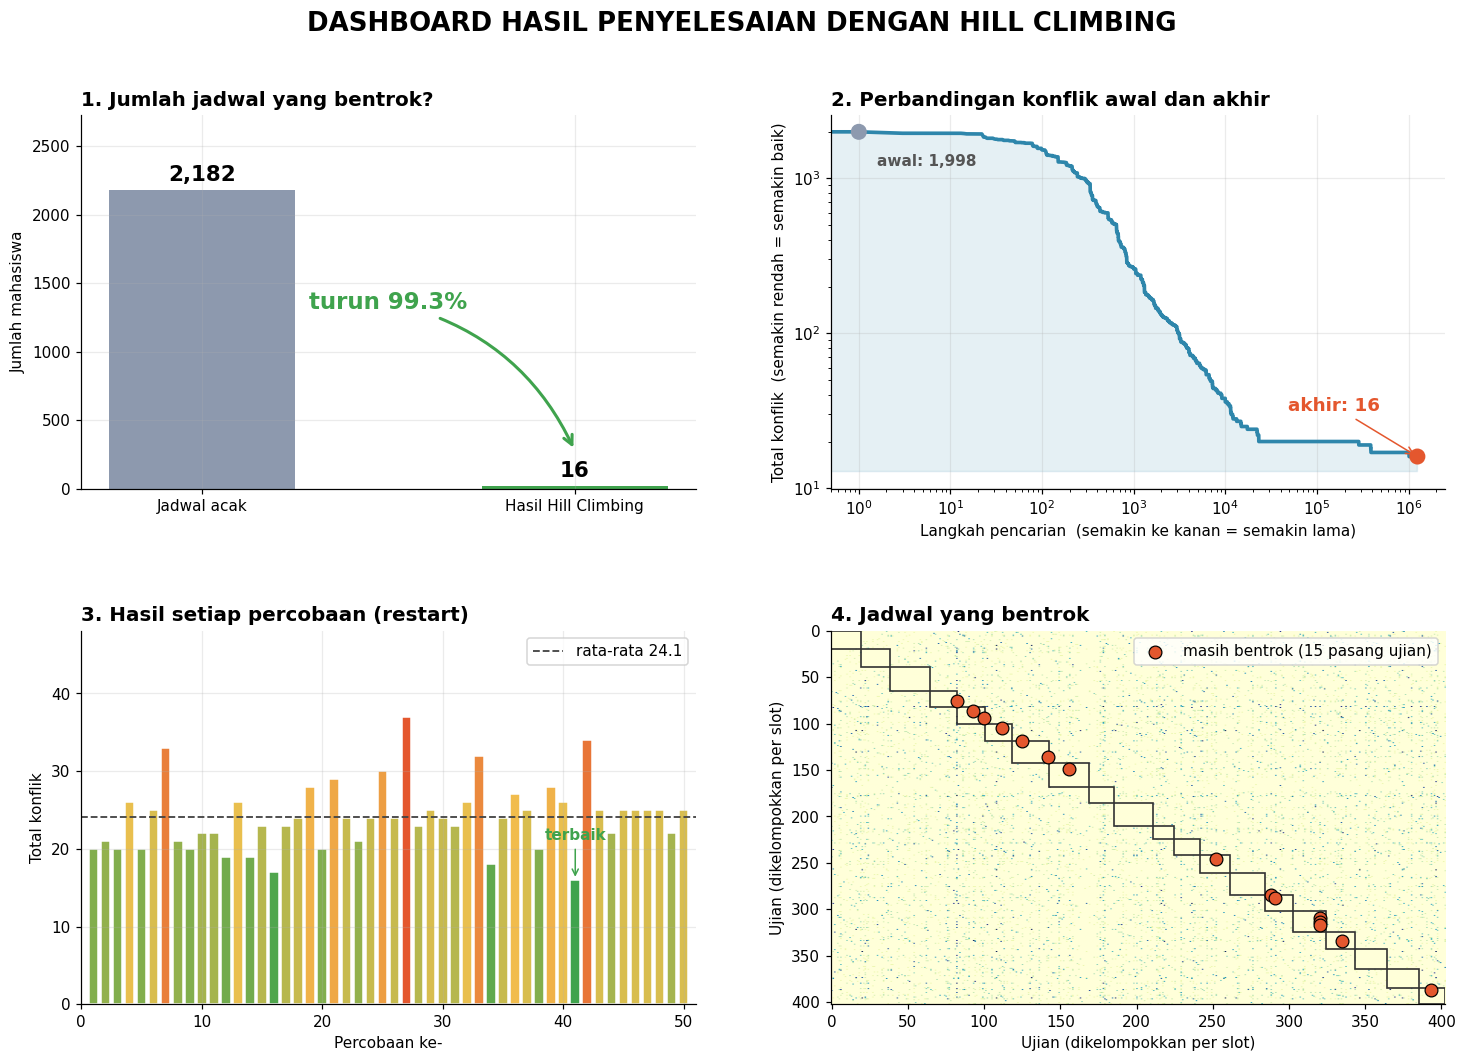

JADWAL UJIAN PER SLOT


Slot,Jumlah Ujian,Daftar Ujian (ID)
1,20,"18, 44, 46, 58, 67, 87, 90, 134, 146, 151, 155, 175, 194, 243, 262, 307, 355, 379, 384, 389"
2,19,"43, 56, 61, 78, 85, 97, 98, 111, 127, 129, 149, 150, 191, 201, 232, 253, 269, 279, 399"
3,26,"10, 22, 53, 74, 100, 117, 118, 144, 156, 184, 217, 224, 237, 255, 256, 259, 263, 289, 297, 303, 350, 351, 380, 390, 396, 397"
4,18,"6, 23, 59, 70, 80, 137, 153, 160, 176, 195, 241, 274, 285, 296, 312, 376, 383, 403"
5,18,"55, 65, 79, 89, 91, 113, 159, 174, 198, 227, 235, 239, 308, 315, 323, 369, 377, 391"
6,18,"15, 34, 135, 177, 200, 205, 207, 213, 219, 230, 245, 261, 283, 302, 357, 366, 382, 392"
7,24,"7, 29, 36, 48, 51, 66, 94, 103, 119, 138, 157, 161, 179, 183, 190, 211, 265, 280, 295, 304, 314, 328, 348, 378"
8,26,"19, 49, 63, 64, 73, 101, 105, 116, 123, 163, 182, 209, 210, 216, 246, 286, 288, 305, 309, 322, 325, 330, 331, 342, 345, 374"
9,17,"20, 26, 50, 71, 81, 92, 121, 125, 231, 272, 278, 293, 316, 341, 358, 386, 387"
10,25,"13, 17, 33, 38, 45, 95, 99, 115, 133, 139, 148, 154, 162, 186, 199, 203, 249, 281, 290, 298, 338, 346, 354, 362, 393"



UJIAN YANG MASIH BENTROK


Ujian A,Ujian B,Slot,Mahasiswa bentrok
200,261,6,2
7,94,7,1
4,114,15,1
77,170,13,1
89,235,5,1
105,216,8,1
11,173,20,1
112,360,16,1
114,168,15,1
192,360,16,1


In [26]:
from IPython.display import HTML
from matplotlib.gridspec import GridSpec
from matplotlib.colors import LinearSegmentedColormap

schedule = np.asarray(hasil["schedule"])
total_mhs = len(students)

mhs_ujian = [[exam_index[int(v)] for v in row if not pd.isna(v)] for row in students.values]

def hitung_mhs_bentrok(jadwal):
    return sum(1 for ujian in mhs_ujian if len(set(jadwal[ujian])) != len(ujian))

bentrok_hc = hitung_mhs_bentrok(schedule)
bentrok_acak = int(np.mean([hitung_mhs_bentrok(random_schedule()) for _ in range(20)]))

same = schedule[:, None] == schedule[None, :]
idx_i, idx_j = np.where(np.triu((conflict > 0) & same, 1))

aman = total_mhs - bentrok_hc
persen_aman = aman / total_mhs * 100

display(HTML(f"""
<div style="font-family:sans-serif; padding:18px 22px; border-radius:12px; background:#3FA34D15; border-left:8px solid #3FA34D; font-size:16px; line-height:1.6;">
    <div style="font-size:13px; color:#555; letter-spacing:1px;">KESIMPULAN</div>
    Dari <b>{total_mhs:,}</b> mahasiswa, <b style="color:#3FA34D;">{aman:,} mahasiswa ({persen_aman:.2f}%)</b> tidak mengalami bentrok jadwal.<br>
    Hanya <b style="color:#E4572E;">{bentrok_hc} mahasiswa</b> yang masih punya dua ujian di waktu yang sama
    (pada {len(idx_i)} pasang ujian).<br>
    Dengan perbandingan jika jadwal yang disusun secara acak maka akan ada sekitar <b>{bentrok_acak:,} mahasiswa</b> yang jadwalnya bentrok.
</div>
"""))

def kartu(judul, nilai, ket, warna):
    return f"""
    <div style="flex:1; min-width:170px; padding:12px 16px; border-radius:10px; background:{warna}15; border-left:6px solid {warna};">
        <div style="font-size:12px; color:#555;">{judul}</div>
        <div style="font-size:26px; font-weight:bold; color:{warna};">{nilai}</div>
        <div style="font-size:12px; color:#777;">{ket}</div>
    </div>"""

display(HTML(f"""
<div style="display:flex; gap:12px; flex-wrap:wrap; font-family:sans-serif; margin-top:10px;">
    {kartu("Mahasiswa bentrok", f"{bentrok_hc}", f"jadwal acak: {bentrok_acak:,}", "#E4572E")}
    {kartu("Mahasiswa aman", f"{persen_aman:.2f}%", f"{aman:,} dari {total_mhs:,}", "#3FA34D")}
    {kartu("Ujian dijadwalkan", f"{n_exams}", f"ke dalam {NUM_SLOTS} slot waktu", "#2E86AB")}
    {kartu("Waktu proses", f"{waktu_hc:.0f} detik", "untuk seluruh pencarian", "#8D99AE")}
</div>
"""))

fig = plt.figure(figsize=(16, 10.5))
fig.patch.set_facecolor("white")
gs = GridSpec(2, 2, figure=fig, hspace=0.38, wspace=0.22)
fig.suptitle("DASHBOARD HASIL PENYELESAIAN DENGAN HILL CLIMBING", fontsize=17, fontweight="bold", y=0.97)

ax1 = fig.add_subplot(gs[0, 0])
nilai = [bentrok_acak, bentrok_hc]
bar = ax1.bar(["Jadwal acak", "Hasil Hill Climbing"], nilai, color=[WARNA["abu"], WARNA["hijau"]], width=0.5)
ax1.set_ylim(0, max(nilai) * 1.25)
ax1.set_ylabel("Jumlah mahasiswa")
ax1.set_title("1. Jumlah jadwal yang bentrok?", loc="left", fontsize=13)
for b, v in zip(bar, nilai):
    ax1.text(b.get_x() + b.get_width() / 2, v + max(nilai) * 0.03, f"{v:,}", ha="center", fontweight="bold", fontsize=14)
turun_mhs = (1 - bentrok_hc / bentrok_acak) * 100
ax1.annotate(f"turun {turun_mhs:.1f}%", xy=(1, bentrok_hc + max(nilai) * 0.12), xytext=(0.5, max(nilai) * 0.6),
             ha="center", fontsize=15, fontweight="bold", color=WARNA["hijau"],
             arrowprops=dict(arrowstyle="->", lw=2, color=WARNA["hijau"], connectionstyle="arc3,rad=-0.25"))

ax2 = fig.add_subplot(gs[0, 1])
hist = np.array(hasil["history"])
ax2.plot(hist, color=WARNA["utama"], lw=2.4)
ax2.fill_between(range(len(hist)), hist, hist.min() * 0.8, color=WARNA["utama"], alpha=0.12)
ax2.set_xscale("log"); ax2.set_yscale("log")
ax2.set_title("2. Perbandingan konflik awal dan akhir", loc="left", fontsize=13)
ax2.set_xlabel("Langkah pencarian  (semakin ke kanan = semakin lama)")
ax2.set_ylabel("Total konflik  (semakin rendah = semakin baik)")
ax2.scatter([1, len(hist)], [hist[0], hist[-1]], color=[WARNA["abu"], WARNA["aksen"]], s=90, zorder=5)
ax2.annotate(f"awal: {hist[0]:,}", xy=(1, hist[0]), xytext=(12, -22), textcoords="offset points", color="#555", fontweight="bold")
ax2.annotate(f"akhir: {hist[-1]}", xy=(len(hist), hist[-1]), xytext=(-85, 30), textcoords="offset points",
             color=WARNA["aksen"], fontweight="bold", fontsize=12, arrowprops=dict(arrowstyle="->", color=WARNA["aksen"]))

ax3 = fig.add_subplot(gs[1, 0])
rc = np.array(hasil["restart_costs"])
terbaik = int(rc.argmin())
cmap_rc = LinearSegmentedColormap.from_list("hr", [WARNA["hijau"], "#F2C14E", WARNA["aksen"]])
norm_rc = (rc - rc.min()) / max(rc.max() - rc.min(), 1)
ax3.bar(range(1, len(rc) + 1), rc, color=cmap_rc(norm_rc), edgecolor="white")
ax3.axhline(rc.mean(), color="#444", ls="--", lw=1.2, label=f"rata-rata {rc.mean():.1f}")
ax3.legend(loc="upper right")
ax3.annotate("terbaik", xy=(terbaik + 1, rc[terbaik]), xytext=(0, 26), textcoords="offset points",
             ha="center", fontweight="bold", color=WARNA["hijau"], arrowprops=dict(arrowstyle="->", color=WARNA["hijau"]))
ax3.set_title("3. Hasil setiap percobaan (restart)", loc="left", fontsize=13)
ax3.set_xlabel("Percobaan ke-"); ax3.set_ylabel("Total konflik")
ax3.set_xlim(0, len(rc) + 1)
ax3.set_ylim(0, rc.max() * 1.3)

ax4 = fig.add_subplot(gs[1, 1])
urut = np.argsort(schedule, kind="stable")
M = conflict[np.ix_(urut, urut)]
ax4.imshow(np.log1p(M), cmap="YlGnBu", aspect="auto", vmax=np.log1p(M).max() * 0.85)
jumlah_slot = np.bincount(schedule, minlength=NUM_SLOTS)
batas = np.cumsum(jumlah_slot)
awal = np.concatenate([[0], batas[:-1]])
for a, b in zip(awal, batas):
    if b > a:
        ax4.add_patch(Rectangle((a - 0.5, a - 0.5), b - a, b - a, fill=False, ec="#333", lw=1.1))
pos = np.empty(n_exams, dtype=int); pos[urut] = np.arange(n_exams)
ax4.scatter(pos[idx_j], pos[idx_i], s=70, color=WARNA["aksen"], edgecolor="black", lw=0.8, zorder=5,
            label=f"masih bentrok ({len(idx_i)} pasang ujian)")
ax4.legend(loc="upper right", frameon=True)
ax4.set_title("4. Jadwal yang bentrok", loc="left", fontsize=13)
ax4.set_xlabel("Ujian (dikelompokkan per slot)"); ax4.set_ylabel("Ujian (dikelompokkan per slot)")
ax4.grid(False)

plt.show()

print("JADWAL UJIAN PER SLOT")
jadwal_slot = pd.DataFrame({
    "Slot": range(1, NUM_SLOTS + 1),
    "Jumlah Ujian": [int((schedule == s).sum()) for s in range(NUM_SLOTS)],
    "Daftar Ujian (ID)": [
        ", ".join(str(exam_ids[i]) for i in np.flatnonzero(schedule == s))
        for s in range(NUM_SLOTS)
    ],
})
display(jadwal_slot.style.hide(axis="index").set_properties(subset=["Daftar Ujian (ID)"], **{"text-align": "left"}))

print("\nUJIAN YANG MASIH BENTROK")
if len(idx_i) > 0:
    tabel_bentrok = pd.DataFrame({
        "Ujian A": [exam_ids[i] for i in idx_i],
        "Ujian B": [exam_ids[j] for j in idx_j],
        "Slot": schedule[idx_i] + 1,
        "Mahasiswa bentrok": conflict[idx_i, idx_j],
    }).sort_values("Mahasiswa bentrok", ascending=False).reset_index(drop=True)
    display(tabel_bentrok.style.hide(axis="index").background_gradient(cmap="Reds", subset=["Mahasiswa bentrok"]))
else:
    print("Tidak ada. Jadwal bebas konflik.")